# Informe de laboratorio · Análisis exploratorio (EDA) del catálogo de Netflix
**Minería de Datos · UNIMINUTO Ibagué · Sesión 5**
**Integrantes:** James Francois Lozano Gordillo · Elian Alexis Sandoval Durán
**Repositorio:** https://github.com/JamesLozano1/Proyecto-Mineria-de-datos

Este notebook es el **anexo reproducible** del informe: ejecuta de principio a fin sobre los dos CSV originales (`CSV/netflix_titles.csv` y `CSV/netflix.csv`) y genera todas las figuras citadas en el informe.

**Contenido:** 1 Portada y contexto · 2 Calidad de datos · 3 Análisis univariado · 4 Análisis bivariado y multivariado · 5 Hallazgos y recomendaciones · 6 Anexos

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Ruta de los CSV: funciona ejecutando desde la raiz del repo o desde notebooks/
CSV_DIR = next(p for p in [Path("CSV"), Path("../CSV"), Path(".")] if (p / "netflix_titles.csv").exists())
FIG_DIR = Path("figs"); FIG_DIR.mkdir(exist_ok=True)

AZUL, NARANJA, GRIS = "#2F4B8A", "#C2410C", "#9AA3B2"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11.5, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "font.size": 10})

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight")
    plt.show()

In [2]:
import numpy as np
import pandas as pd

RATINGS_VALIDOS = ["G", "PG", "PG-13", "R", "NC-17", "TV-Y", "TV-Y7", "TV-Y7-FV",
                   "TV-G", "TV-PG", "TV-14", "TV-MA", "NR", "UR"]


def limpiar_titulos(raw):
    """Replica el pipeline del proyecto (LimpiadorDatos) con la correccion de fechas."""
    info = {"n_original": len(raw), "duplicados": int(raw.duplicated().sum())}
    d = raw.drop_duplicates().copy()
    for c in ["director", "cast", "country", "rating", "duration"]:
        d[c] = d[c].fillna("Desconocido")
    # Correccion: algunas fechas traen un espacio inicial (" August 4, 2017").
    # Sin strip(), pandas infiere el formato de la primera fila y convierte esas en NaT.
    sin_strip = pd.to_datetime(raw["date_added"], errors="coerce")
    info["fechas_nulas_original"] = int(raw["date_added"].isna().sum())
    info["fechas_nulas_sin_strip"] = int(sin_strip.isna().sum())
    d["date_added"] = pd.to_datetime(d["date_added"].str.strip(), errors="coerce", format="mixed")
    sus = (~d["rating"].isin(RATINGS_VALIDOS)) & (d["rating"] != "Desconocido")
    info["ratings_sospechosos"] = d.loc[sus, ["title", "type", "rating"]].copy()
    d.loc[sus, "duration"] = d.loc[sus, "rating"]
    d.loc[sus, "rating"] = "Desconocido"
    d["durationValue"] = pd.to_numeric(d["duration"].str.split(" ").str[0], errors="coerce")
    d["added_year"] = d["date_added"].dt.year
    d["antiguedad"] = d["added_year"] - d["release_year"]
    d["pais_principal"] = d["country"].str.split(", ").str[0]
    d["prod_internacional"] = ~d["pais_principal"].isin(["United States", "Desconocido"])
    d["rating_adulto"] = d["rating"].isin(["TV-MA", "R", "NC-17"])
    return d, info


def limpiar_valoraciones(raw):
    info = {"n_original": len(raw), "duplicados": int(raw.duplicated().sum())}
    v = raw.drop_duplicates().copy()
    v["rating"] = v["rating"].fillna("Desconocido")
    return v, info


def estadisticos(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    lo, hi = q1 - 1.5 * i, q3 + 1.5 * i
    return {"n": int(len(s)), "media": s.mean(), "mediana": s.median(), "desv": s.std(),
            "min": s.min(), "max": s.max(), "asimetria": s.skew(), "curtosis": s.kurt(),
            "Q1": q1, "Q3": q3, "lim_inf": lo, "lim_sup": hi,
            "outliers": int(((s < lo) | (s > hi)).sum())}


def explotar(d, col):
    x = d.copy()
    x[col] = x[col].str.split(", ")
    x = x.explode(col)
    x[col] = x[col].str.strip()
    return x


def es(x, dec=1):
    """Formato espanol: punto de miles y coma decimal."""
    t = f"{x:,.{dec}f}"
    return t.replace(",", "X").replace(".", ",").replace("X", ".")

In [3]:
raw = pd.read_csv(CSV_DIR / "netflix_titles.csv")
rawv = pd.read_csv(CSV_DIR / "netflix.csv")
d, info = limpiar_titulos(raw)
v, vinfo = limpiar_valoraciones(rawv)
mv, tv = d[d.type == "Movie"], d[d.type == "TV Show"]
print(f"Catalogo: {len(raw)} filas x {raw.shape[1]} columnas  |  Valoraciones: {len(rawv)} filas x {rawv.shape[1]} columnas")
print(f"Peliculas: {len(mv)} ({len(mv)/len(d):.1%})  |  Series: {len(tv)} ({len(tv)/len(d):.1%})")

Catalogo: 8807 filas x 12 columnas  |  Valoraciones: 1000 filas x 7 columnas
Peliculas: 6131 (69.6%)  |  Series: 2676 (30.4%)


## 1 · Portada y contexto

**Contexto.** Netflix publica un catálogo con miles de títulos. Trabajamos con dos fuentes: `netflix_titles.csv` (8.807 títulos, 12 columnas) y `netflix.csv` (1.000 registros de valoraciones de usuarios, 7 columnas, de los que quedan 500 tras eliminar duplicados). El pipeline Python del proyecto (`LectorDatos`, `LimpiadorDatos`, `AnalizadorDatos`, `VisualizadorDatos`, `ExportadorDatos`) ya entrega el dataset limpio; este informe lo explora.

**Pregunta de negocio.** ¿Cómo ha cambiado la composición del catálogo de Netflix con el tiempo, y qué distingue a los títulos que llegan más rápido a la plataforma, los de producción internacional y los mejor valorados por los usuarios?

**Objetivos del análisis**
1. Evaluar la calidad de los datos (nulos, duplicados, outliers) y documentar las decisiones tomadas.
2. Describir cada variable numérica y categórica relevante (tendencia central, dispersión y forma).
3. Relacionar variables entre sí: tiempo de llegada al catálogo, tipo de contenido, país, clasificación, género y valoración.
4. Formular y validar con datos hipótesis sobre el crecimiento, la internacionalización y la valoración.

**Variable de segmentación.** El dataset no tiene una variable objetivo supervisada. Usamos `type` (película o serie) como variable de cruce principal y `user_rating_score` como resultado de interés en el análisis de valoraciones.

## 2 · Calidad de datos

In [4]:
def tabla_nulos(df):
    t = df.isna().sum().to_frame("nulos")
    t["% del total"] = (t["nulos"] / len(df) * 100).round(2)
    return t[t["nulos"] > 0]

print("NULOS en netflix_titles.csv (original)"); display(tabla_nulos(raw))
print("\nNULOS en netflix.csv (original)"); display(tabla_nulos(rawv))
print(f"\nDuplicados exactos  ->  catalogo: {info['duplicados']}   |   valoraciones: {vinfo['duplicados']} de {vinfo['n_original']}")

NULOS en netflix_titles.csv (original)


,nulos,% del total
director,2634,29.91
cast,825,9.37
country,831,9.44
date_added,10,0.11
rating,4,0.05
duration,3,0.03



NULOS en netflix.csv (original)


,nulos,% del total
ratingdescription,59,5.9
user_rating_score,395,39.5



Duplicados exactos  ->  catalogo: 0   |   valoraciones: 500 de 1000


In [5]:
print("FECHAS date_added")
print(f"  Nulos reales en el CSV original      : {info['fechas_nulas_original']}")
print(f"  Nulos tras to_datetime SIN strip()   : {info['fechas_nulas_sin_strip']}")
print(f"  Fechas perdidas solo por el formato  : {info['fechas_nulas_sin_strip'] - info['fechas_nulas_original']}")
print("  Ejemplo de valor afectado:", repr(raw.loc[pd.to_datetime(raw.date_added, errors='coerce').isna() & raw.date_added.notna(), 'date_added'].iloc[0]))
print("\nRATINGS SOSPECHOSOS (la duracion quedo guardada en la columna rating)")
display(info["ratings_sospechosos"])

FECHAS date_added
  Nulos reales en el CSV original      : 10
  Nulos tras to_datetime SIN strip()   : 98
  Fechas perdidas solo por el formato  : 88
  Ejemplo de valor afectado: ' August 4, 2017'

RATINGS SOSPECHOSOS (la duracion quedo guardada en la columna rating)


,title,type,rating
5541,Louis C.K. 2017,Movie,74 min
5794,Louis C.K.: Hilarious,Movie,84 min
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min


In [6]:
variables = {
    "release_year": d.release_year,
    "durationValue (películas, min)": mv.durationValue,
    "durationValue (series, temporadas)": tv.durationValue,
    "added_year": d.added_year,
    "antiguedad_al_agregar (años)": d.antiguedad,
    "user_rating_score": v.user_rating_score,
}
T = pd.DataFrame({k: estadisticos(s) for k, s in variables.items()}).T
print("OUTLIERS por la regla del IQR (fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR])")
out = T[["n", "Q1", "Q3", "lim_inf", "lim_sup", "outliers"]].copy()
out["% outliers"] = (T["outliers"] / T["n"] * 100).round(1)
display(out.round(1))
print(f"Titulos con antiguedad negativa (agregados antes de su release_year): {(d.antiguedad < 0).sum()}")

OUTLIERS por la regla del IQR (fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR])


,n,Q1,Q3,lim_inf,lim_sup,outliers,% outliers
release_year,8807.0,2013.0,2019.0,2004.0,2028.0,719.0,8.2
"durationValue (películas, min)",6131.0,87.0,114.0,46.5,154.5,450.0,7.3
"durationValue (series, temporadas)",2676.0,1.0,2.0,-0.5,3.5,259.0,9.7
added_year,8797.0,2018.0,2020.0,2015.0,2023.0,56.0,0.6
antiguedad_al_agregar (años),8797.0,0.0,5.0,-7.5,12.5,972.0,11.0
user_rating_score,256.0,71.0,93.0,38.0,126.0,0.0,0.0


Titulos con antiguedad negativa (agregados antes de su release_year): 14


**Decisiones tomadas (herencia de las sesiones 3 y 4)**

| Problema | Evidencia | Decisión |
|---|---|---|
| `director`, `cast`, `country` con nulos | 2.634, 825 y 831 filas | Se reemplazan por `"Desconocido"` para no perder el resto de la fila. `country` desconocido es 9,4% del catálogo y aparece como tercer "país" en los rankings. |
| Fechas `date_added` perdidas por formato | 88 fechas válidas se convertían en nulo por un espacio inicial (`" August 4, 2017"`) | **Corrección: aplicar str.strip() antes de to_datetime.** Quedan 10 nulos reales en vez de 98. |
| `rating` con la duración | 3 especiales de Louis C.K. con `"74 min"`, `"84 min"` y `"66 min"` en `rating` | Se mueve el valor a `duration` y `rating` pasa a `"Desconocido"`. |
| Antigüedad negativa | 14 títulos | Se conservan: son una particularidad del dataset (en las series `release_year` refleja la última temporada). |
| Duplicados en valoraciones | 500 de 1.000 filas (50%) | Se eliminan. Es una proporción alta, posible problema de carga del archivo original. |
| `user_rating_score` nulo | 395 nulos en el original; 256 valores válidos tras deduplicar | Se analizan solo los registros con puntuación; no se imputa. |
| Outliers | ver tabla IQR arriba | **No se eliminan:** son títulos reales (especiales de 3 minutos, series de 17 temporadas). Se reportan con mediana. |

> **Impacto de la corrección de fechas.** Con la conversión original se perdían 88 títulos del análisis temporal (8.709 en vez de 8.797). Todas las cifras de este informe usan la versión corregida.

## 3 · Análisis univariado

In [7]:
desc = T[["n", "media", "mediana", "desv", "min", "max", "asimetria", "curtosis"]].round(2)
display(desc)

,n,media,mediana,desv,min,max,asimetria,curtosis
release_year,8807.0,2014.18,2017.0,8.82,1925.0,2021.0,-3.45,16.23
"durationValue (películas, min)",6131.0,99.56,98.0,28.29,3.0,312.0,0.20,2.29
"durationValue (series, temporadas)",2676.0,1.76,1.0,1.58,1.0,17.0,3.42,16.13
added_year,8797.0,2018.87,2019.0,1.57,2008.0,2021.0,-0.70,1.32
antiguedad_al_agregar (años),8797.0,4.69,1.0,8.79,-3.0,93.0,3.51,16.19
user_rating_score,256.0,81.40,83.5,12.73,55.0,99.0,-0.48,-0.96


**Lectura de la tabla.** La duración de las películas es casi simétrica (asimetría 0,20, media 99,6 y mediana 98 min). Las series, la antigüedad y el año de lanzamiento no lo son: `antiguedad_al_agregar` tiene media 4,7 y mediana 1, con asimetría 3,51 y curtosis 16,2; `release_year` tiene asimetría -3,45 (cola hacia títulos antiguos). En esas variables conviene reportar la **mediana**.

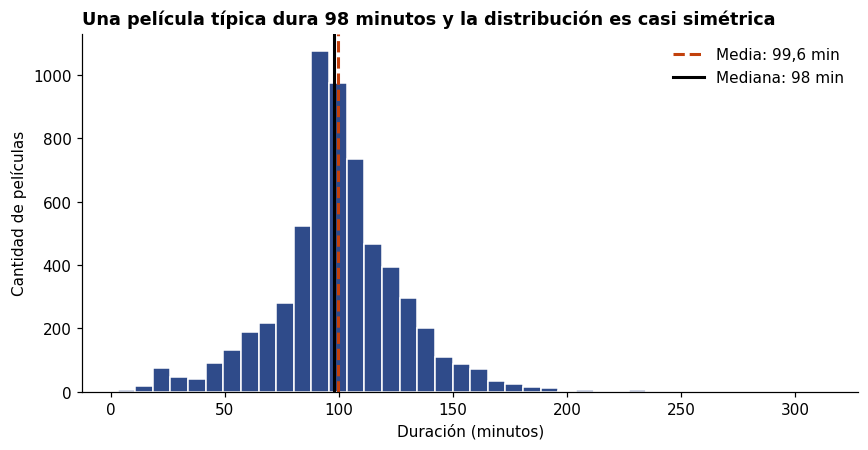

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(mv.durationValue, bins=40, color=AZUL, edgecolor="white")
ax.axvline(mv.durationValue.mean(), color=NARANJA, ls="--", lw=2, label=f"Media: {es(mv.durationValue.mean())} min")
ax.axvline(mv.durationValue.median(), color="black", lw=2, label=f"Mediana: {es(mv.durationValue.median(),0)} min")
ax.set_title(f"Una película típica dura {es(mv.durationValue.median(),0)} minutos y la distribución es casi simétrica")
ax.set_xlabel("Duración (minutos)"); ax.set_ylabel("Cantidad de películas"); ax.legend(frameon=False)
guardar("fig01_hist_duracion_peliculas")

**Figura 1 · Interpretación.** La masa principal está entre 87 y 114 minutos (el 50% central). Media y mediana casi coinciden (99,6 vs 98), coherente con asimetría baja. Según el IQR hay 450 películas atípicas (7,3%), por debajo de 46,5 o sobre 154,5 minutos: especiales de stand-up muy cortos y documentales o películas épicas de hasta 312 minutos. Son datos reales y se conservan.

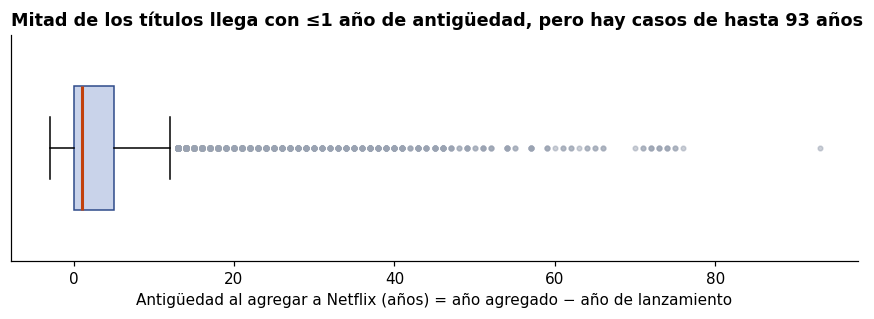

In [9]:
a = d.antiguedad.dropna()
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot(a, vert=False, widths=.55, patch_artist=True, boxprops=dict(facecolor="#C9D3EA", color=AZUL),
           medianprops=dict(color=NARANJA, lw=2), flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS, alpha=.5))
ax.set_title(f"Mitad de los títulos llega con ≤{es(a.median(),0)} año de antigüedad, pero hay casos de hasta {es(a.max(),0)} años")
ax.set_xlabel("Antigüedad al agregar a Netflix (años) = año agregado − año de lanzamiento"); ax.set_yticks([])
guardar("fig02_boxplot_antiguedad")

**Figura 2 · Interpretación.** La caja es muy estrecha (Q1 = 0, Q3 = 5) y la mediana es 1 año: **55% de los títulos llega con un año o menos** y 37% el mismo año de su lanzamiento. El bigote superior llega a 12,5 años y hay 972 outliers (11%), el catálogo de fondo (clásicos hasta 93 años). La media (4,7) queda arrastrada por esa cola, así que se reporta la mediana.

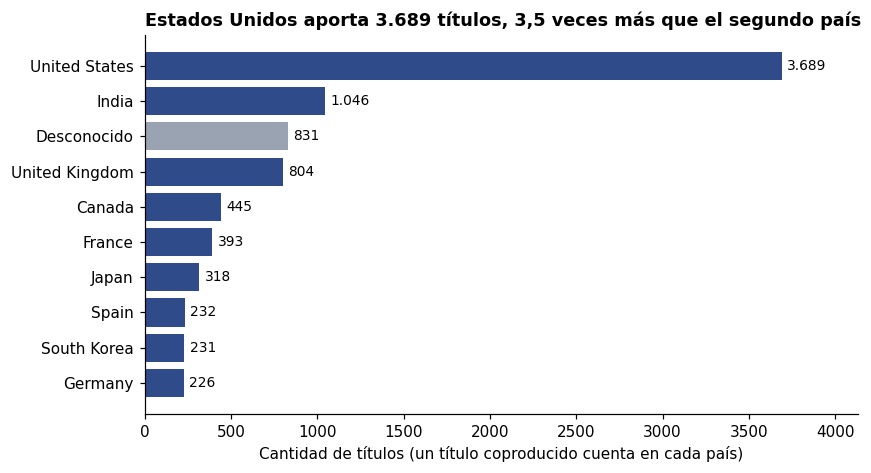

In [10]:
p = explotar(d, "country")["country"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(p.index, p.values, color=[GRIS if i == "Desconocido" else AZUL for i in p.index])
for y, val in enumerate(p.values): ax.text(val + 30, y, f"{val:,}".replace(",", "."), va="center", fontsize=9)
ax.set_title(f"Estados Unidos aporta {es(p.iloc[-1],0)} títulos, {es(p.iloc[-1]/p.iloc[-2])} veces más que el segundo país")
ax.set_xlabel("Cantidad de títulos (un título coproducido cuenta en cada país)"); ax.set_xlim(0, p.max() * 1.12)
guardar("fig03_barras_paises")

**Figura 3 · Interpretación.** Estados Unidos lidera con 3.689 títulos, seguido de India (1.046) y, en tercer lugar, **"Desconocido" (831)**, es decir, la falta de dato pesa más que Reino Unido (804). La concentración es alta: Estados Unidos, India y Reino Unido suman 3,0 veces lo que suman los otros seis países reales del ranking. Como un título coproducido cuenta en varios países, las barras no suman el total de títulos.

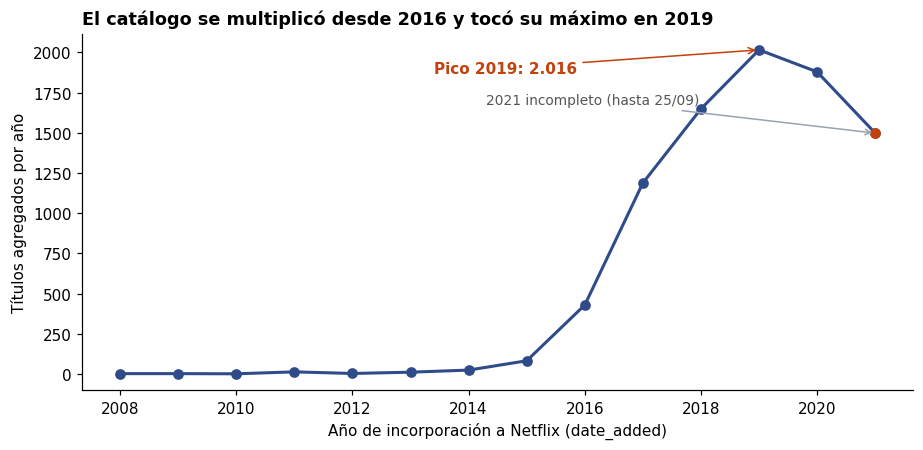

In [11]:
ay = d.added_year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(ay.index, ay.values, marker="o", color=AZUL, lw=2)
pk = ay.idxmax(); ax.annotate(f"Pico {int(pk)}: {ay.max():,}".replace(",", "."), (pk, ay.max()), xytext=(pk - 5.6, ay.max() * .93), arrowprops=dict(arrowstyle="->", color=NARANJA), color=NARANJA, fontweight="bold")
ax.scatter([2021], [ay[2021]], color=NARANJA, zorder=3); ax.annotate(f"2021 incompleto (hasta {d.date_added.max():%d/%m})", (2021, ay[2021]), xytext=(2014.3, ay[2021] * 1.12), arrowprops=dict(arrowstyle="->", color=GRIS), color="#555", fontsize=9)
ax.set_title(f"El catálogo se multiplicó desde 2016 y tocó su máximo en {int(pk)}")
ax.set_xlabel("Año de incorporación a Netflix (date_added)"); ax.set_ylabel("Títulos agregados por año")
guardar("fig04_linea_titulos_por_anio")

**Figura 4 · Interpretación.** Hasta 2015 se agregaban menos de 100 títulos por año (82 en 2015). En 2016 la cifra salta a 429 y llega al **máximo en 2019 con 2.016 títulos**. En 2020 baja a 1.879 (−6,8% frente a 2019, único descenso de un año completo). El dato de 2021 (1.498) no es comparable porque el registro termina el 25/09/2021.

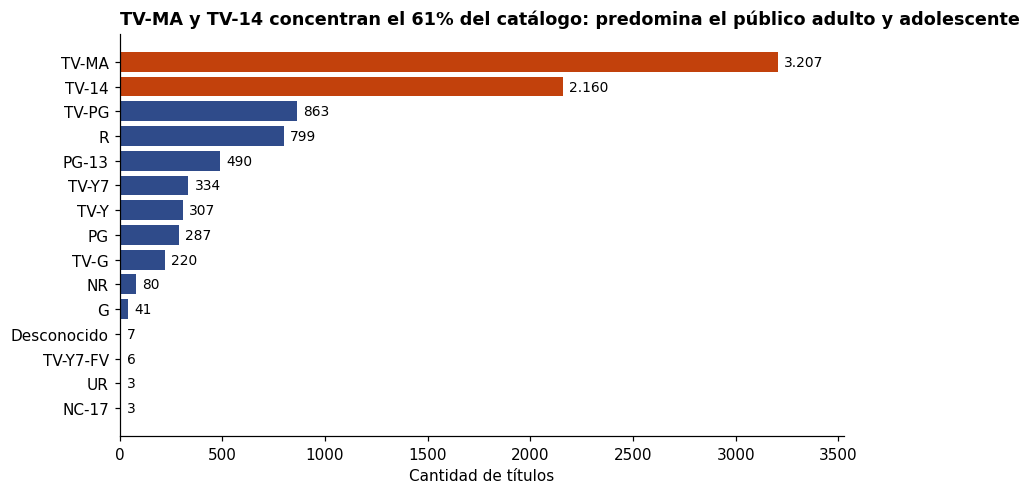

In [12]:
r = d["rating"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
cols = [NARANJA if i in ("TV-MA", "TV-14") else AZUL for i in r.index]
ax.barh(r.index, r.values, color=cols)
for y, val in enumerate(r.values): ax.text(val + 30, y, f"{val:,}".replace(",", "."), va="center", fontsize=9)
share = d["rating"].isin(["TV-MA", "TV-14"]).mean()
ax.set_title(f"TV-MA y TV-14 concentran el {share*100:.0f}% del catálogo: predomina el público adulto y adolescente".replace(".", ","))
ax.set_xlabel("Cantidad de títulos"); ax.set_xlim(0, r.max() * 1.1)
guardar("fig05_barras_clasificacion")

**Figura 5 · Interpretación.** TV-MA (3.207) y TV-14 (2.160) suman el **61%** de los títulos. Las clasificaciones infantiles son minoritarias (TV-Y7 3,8%, TV-Y 3,5%, TV-G 2,5%) y NC-17 y UR casi no existen (3 títulos cada una). Quedan 7 títulos con clasificación desconocida tras la corrección.

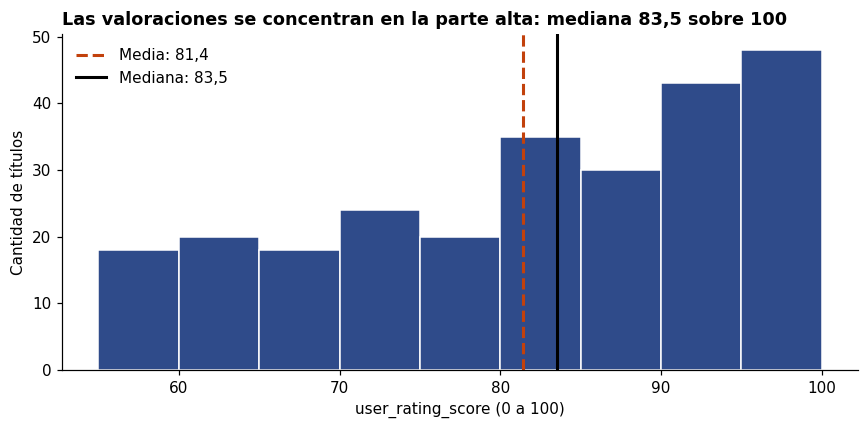

In [13]:
sv = v.user_rating_score.dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sv, bins=np.arange(55, 105, 5), color=AZUL, edgecolor="white")
ax.axvline(sv.mean(), color=NARANJA, ls="--", lw=2, label=f"Media: {es(sv.mean())}")
ax.axvline(sv.median(), color="black", lw=2, label=f"Mediana: {es(sv.median())}")
ax.set_title(f"Las valoraciones se concentran en la parte alta: mediana {es(sv.median())} sobre 100")
ax.set_xlabel("user_rating_score (0 a 100)"); ax.set_ylabel("Cantidad de títulos"); ax.legend(frameon=False, loc="upper left")
guardar("fig06_hist_valoraciones")

**Figura 6 · Interpretación.** Con 256 valoraciones válidas, la media es 81,4 y la mediana 83,5: la mediana supera a la media y la asimetría es negativa (-0,48): hay una cola hacia notas bajas. El mínimo es 55: **ningún título baja de 55**, lo que podría indicar que el dataset ya viene filtrado por calidad (no podemos confirmarlo con estos datos). Hay 0 outliers por IQR.

## 4 · Análisis bivariado y multivariado

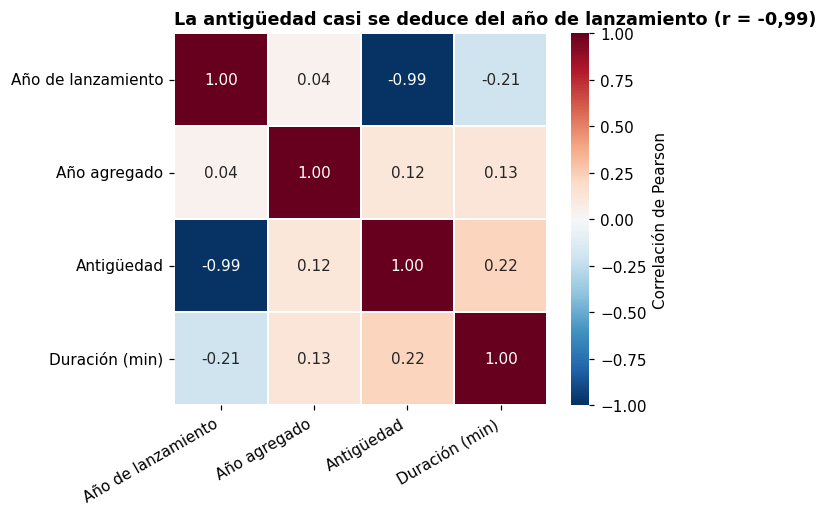

In [14]:
c = mv.dropna(subset=["added_year"])[["release_year", "added_year", "antiguedad", "durationValue"]].corr()
c.columns = c.index = ["Año de lanzamiento", "Año agregado", "Antigüedad", "Duración (min)"]
fig, ax = plt.subplots(figsize=(6.2, 4.8))
sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=1, cbar_kws={"label": "Correlación de Pearson"}, ax=ax)
ax.set_title(f"La antigüedad casi se deduce del año de lanzamiento (r = {c.iloc[0, 2]:.2f})".replace(".", ","))
plt.xticks(rotation=30, ha="right")
guardar("fig07_heatmap_correlaciones")

**Figura 7 · Interpretación (películas).** La correlación entre `release_year` y `antiguedad_al_agregar` es **-0,99**: es una relación casi exacta porque la antigüedad se calcula como año agregado menos año de lanzamiento. Es la misma redundancia que reveló el PCA en la sesión 4 (rango 3 en 4 variables). El resto de correlaciones es débil: la duración se asocia levemente con la antigüedad (r = 0,22), es decir, las películas largas tienden a ser más antiguas, y no con el año agregado (r = 0,13). *Esto es asociación lineal, no causalidad.* La duración mezcla minutos (películas) y temporadas (series), por eso solo se correlaciona en películas.

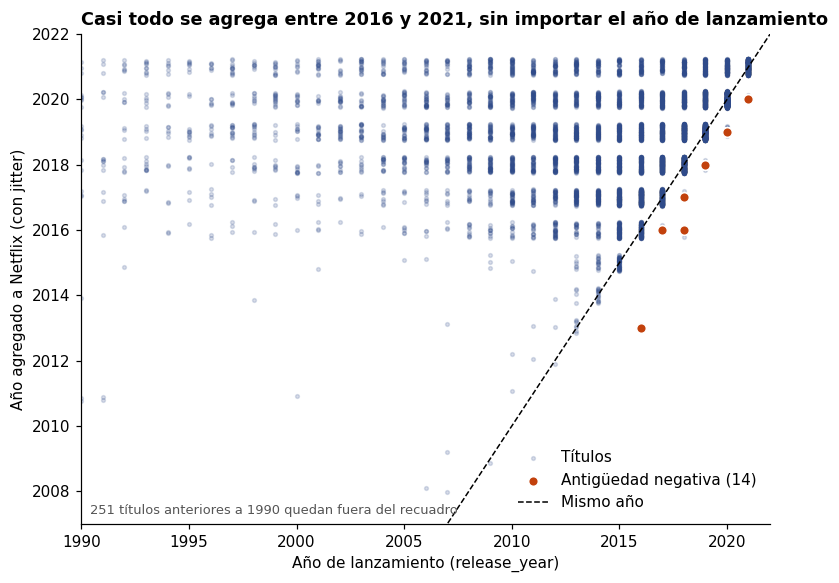

Spearman release_year vs added_year: rho = 0.37  (p = 7.9e-288)


In [15]:
x = d.dropna(subset=["added_year"])
fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.scatter(x.release_year, x.added_year + np.random.default_rng(0).uniform(-.25, .25, len(x)), s=6, alpha=.18, color=AZUL, label="Títulos")
neg = x[x.antiguedad < 0]
ax.scatter(neg.release_year, neg.added_year, s=40, color=NARANJA, edgecolor="white", zorder=3, label=f"Antigüedad negativa ({len(neg)})")
ax.plot([1990, 2022], [1990, 2022], color="black", lw=1, ls="--", label="Mismo año")
ax.set_xlim(1990, 2022); ax.set_ylim(2007, 2022)
fuera = (x.release_year < 1990).sum()
ax.set_title("Casi todo se agrega entre 2016 y 2021, sin importar el año de lanzamiento")
ax.set_xlabel("Año de lanzamiento (release_year)"); ax.set_ylabel("Año agregado a Netflix (con jitter)")
ax.text(1990.4, 2007.3, f"{fuera} títulos anteriores a 1990 quedan fuera del recuadro", fontsize=8.5, color="#555")
ax.legend(frameon=False, loc="lower right")
guardar("fig08_dispersion_lanzamiento_vs_agregado")
rho = stats.spearmanr(x.release_year, x.added_year)
print(f"Spearman release_year vs added_year: rho = {rho.statistic:.2f}  (p = {rho.pvalue:.1e})")

**Figura 8 · Interpretación.** Los puntos forman franjas horizontales entre 2016 y 2021: sea cual sea el año de lanzamiento (incluso décadas atrás), el título entra casi siempre en ese período. Solo en la esquina superior derecha tocan la diagonal: ahí están el 37% de títulos que llegan el mismo año de su estreno. Los 14 puntos naranja bajo la diagonal son los casos de antigüedad negativa: 12 series (cuyo `release_year` registra la temporada más reciente) y 2 películas (probables errores de captura). La correlación de Spearman entre ambos años es moderada (ρ = 0,37, calculada en la celda), porque el año de incorporación casi no depende del año de lanzamiento.

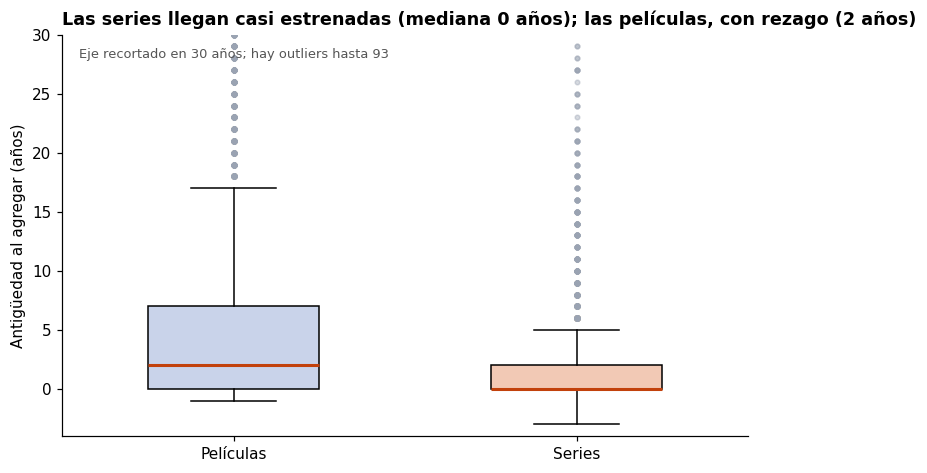

In [16]:
x = d.dropna(subset=["antiguedad"])
fig, ax = plt.subplots(figsize=(7, 4.4))
bp = ax.boxplot([x[x.type == t].antiguedad for t in ["Movie", "TV Show"]], labels=["Películas", "Series"], patch_artist=True, widths=.5,
                medianprops=dict(color=NARANJA, lw=2), flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS, alpha=.4))
for b, c_ in zip(bp["boxes"], ["#C9D3EA", "#F2C9B5"]): b.set_facecolor(c_)
ax.set_ylim(-4, 30)
med = x.groupby("type").antiguedad.median()
ax.set_title(f"Las series llegan casi estrenadas (mediana {med['TV Show']:.0f} años); las películas, con rezago ({med['Movie']:.0f} años)")
ax.set_ylabel("Antigüedad al agregar (años)")
ax.text(.55, 28, "Eje recortado en 30 años; hay outliers hasta 93", fontsize=8.5, color="#555")
guardar("fig09_boxplot_antiguedad_por_tipo")

**Figura 9 · Interpretación.** La mediana de antigüedad es **0 años en series y 2 en películas**; 52% de las series se agrega el mismo año de su lanzamiento frente a 30% de las películas. Las películas tienen además la cola larga de clásicos. La diferencia es estadísticamente significativa (Mann-Whitney, p < 0,001).

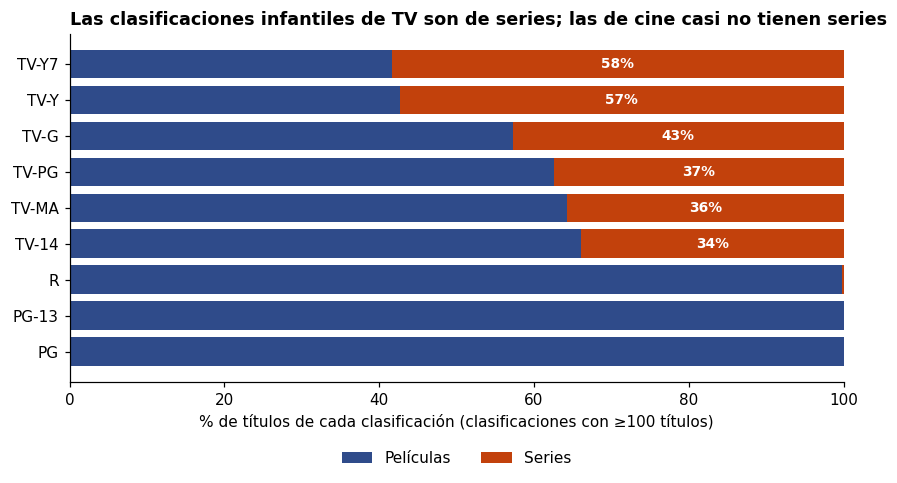

type,Movie,TV Show,total
rating,,,
PG,287,0,287
PG-13,490,0,490
R,797,2,799
TV-14,1427,733,2160
TV-G,126,94,220
TV-MA,2062,1145,3207
TV-PG,540,323,863
TV-Y,131,176,307
TV-Y7,139,195,334


In [17]:
t = pd.crosstab(d.rating, d.type)
t = t[t.sum(axis=1) >= 100]
pct = t.div(t.sum(axis=1), axis=0).mul(100).sort_values("TV Show")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(pct.index, pct["Movie"], color=AZUL, label="Películas")
ax.barh(pct.index, pct["TV Show"], left=pct["Movie"], color=NARANJA, label="Series")
for y, (m_, s_) in enumerate(zip(pct["Movie"], pct["TV Show"])):
    if s_ > 8: ax.text(m_ + s_ / 2, y, f"{s_:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
ax.set_title("Las clasificaciones infantiles de TV son de series; las de cine casi no tienen series")
ax.set_xlabel("% de títulos de cada clasificación (clasificaciones con ≥100 títulos)"); ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(.5, -.28))
guardar("fig10_clasificacion_por_tipo")
display(t.assign(total=t.sum(axis=1)))

**Figura 10 · Interpretación.** Cruce de `rating` con `type`. PG, PG-13 y R pertenecen casi por completo a películas (clasificaciones de cine), mientras que TV-Y (57% series) y TV-Y7 (58%) son mayoritariamente series: el contenido infantil de Netflix es sobre todo serializado. TV-MA se reparte 64% películas y 36% series.

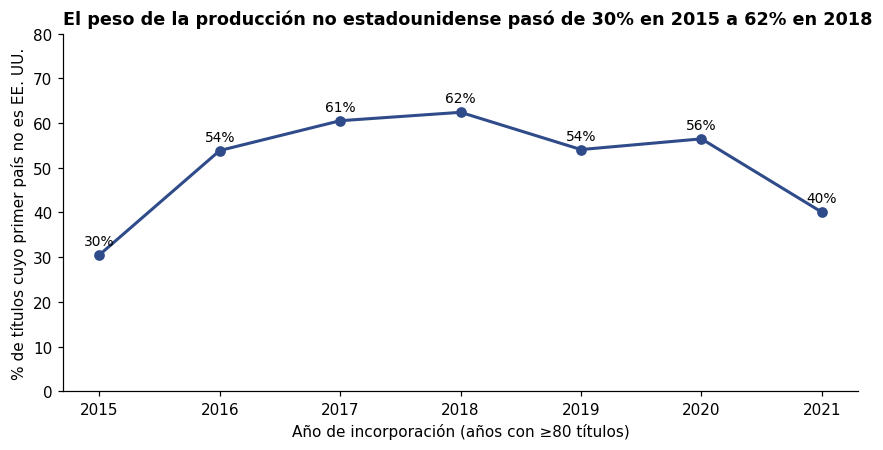

In [18]:
g = d.dropna(subset=["added_year"]).groupby("added_year").prod_internacional.agg(["mean", "size"])
g = g[g["size"] >= 80]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(g.index, g["mean"] * 100, marker="o", color=AZUL, lw=2)
for xx, yy in zip(g.index, g["mean"] * 100): ax.text(xx, yy + 2.2, f"{yy:.0f}%", ha="center", fontsize=9)
ax.set_ylim(0, 80)
ax.set_title(f"El peso de la producción no estadounidense pasó de {g['mean'].iloc[0]*100:.0f}% en 2015 a {g['mean'].max()*100:.0f}% en {int(g['mean'].idxmax())}")
ax.set_xlabel("Año de incorporación (años con ≥80 títulos)"); ax.set_ylabel("% de títulos cuyo primer país no es EE. UU.")
guardar("fig11_internacionalizacion")

**Figura 11 · Interpretación.** Definimos la variable nueva `prod_internacional` (el primer país listado no es Estados Unidos ni "Desconocido"). Pasó de 30% en 2015 a 62% en 2018, y se mantiene entre 54% y 56% en 2019-2020. El 40% de 2021 no se interpreta como retroceso: ese año el país desconocido sube a 24% de los títulos (entre 4% y 8% en 2016-2019) y el año está incompleto.

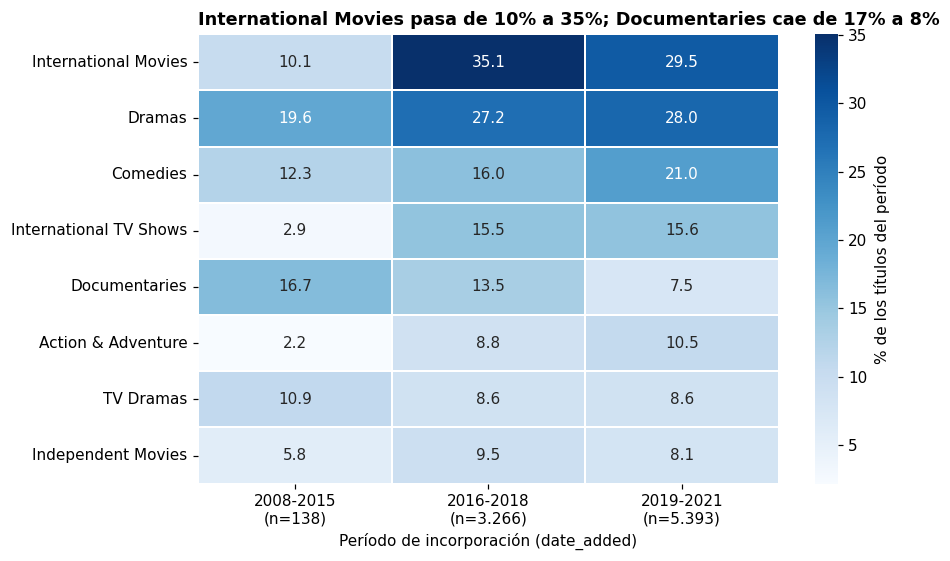

In [19]:
dg = explotar(d, "listed_in").dropna(subset=["added_year"])
top8 = explotar(d, "listed_in")["listed_in"].value_counts().head(8).index
per = {"2008-2015": (2008, 2015), "2016-2018": (2016, 2018), "2019-2021": (2019, 2021)}
filas = {}
for lab, (a_, b_) in per.items():
    nt = d[(d.added_year >= a_) & (d.added_year <= b_)].show_id.nunique()
    sub = dg[(dg.added_year >= a_) & (dg.added_year <= b_) & dg.listed_in.isin(top8)]
    filas[f"{lab}\n(n={nt:,})".replace(",", ".")] = (sub.groupby("listed_in").show_id.nunique() / nt * 100).reindex(top8)
H = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(8.6, 5.2))
sns.heatmap(H, annot=True, fmt=".1f", cmap="Blues", linewidths=1, cbar_kws={"label": "% de los títulos del período"}, ax=ax)
ax.set_title(f"International Movies pasa de {H.iloc[0,0]:.0f}% a {H.iloc[0,1]:.0f}%; Documentaries cae de {H.loc['Documentaries'].iloc[0]:.0f}% a {H.loc['Documentaries'].iloc[2]:.0f}%")
ax.set_ylabel(""); ax.set_xlabel("Período de incorporación (date_added)")
guardar("fig12_genero_por_periodo")

**Figura 12 · Interpretación.** Cada celda es el % de títulos del período que tiene ese género (un título puede tener varios). *International Movies* pasa de 10,1% a 35,1% y se mantiene en 29,5%; *International TV Shows* de 2,9% a 15,6%. *Documentaries* cae de 16,7% a 7,5%. *Comedies* crece de 12,3% a 21,0%. Precaución: el período 2008-2015 tiene solo 138 títulos.

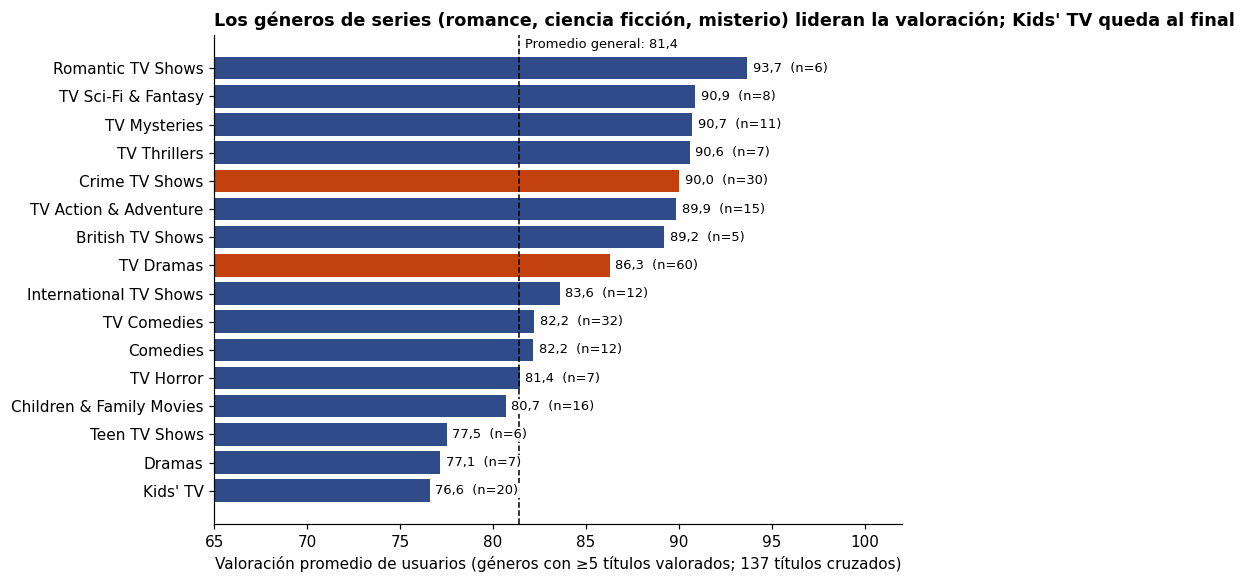

In [20]:
vv = v.dropna(subset=["user_rating_score"])
uniq = d.drop_duplicates(subset=["title"])[["title", "listed_in", "type"]]
m = vv.merge(uniq, on="title", how="inner")
mg = explotar(m, "listed_in").groupby("listed_in").user_rating_score.agg(["count", "mean"])
mg = mg[mg["count"] >= 5].sort_values("mean")
fig, ax = plt.subplots(figsize=(8.4, 5.4))
ax.barh(mg.index, mg["mean"], color=[NARANJA if k >= 20 and mm >= 85 else AZUL for k, mm in zip(mg["count"], mg["mean"])])
for y, (k, mm) in enumerate(zip(mg["count"], mg["mean"])): ax.text(mm + .3, y, f"{mm:.1f}  (n={k})".replace(".", ","), va="center", fontsize=8.5, bbox=dict(fc="white", ec="none", pad=.6, alpha=.9), zorder=4)
ax.axvline(vv.user_rating_score.mean(), color="black", ls="--", lw=1)
ax.text(vv.user_rating_score.mean() + .3, len(mg) - .4, f"Promedio general: {es(vv.user_rating_score.mean())}", fontsize=8.5, va="bottom")
ax.set_xlim(65, 102)
ax.set_title("Los géneros de series (romance, ciencia ficción, misterio) lideran la valoración; Kids' TV queda al final")
ax.set_xlabel(f"Valoración promedio de usuarios (géneros con ≥5 títulos valorados; {len(m)} títulos cruzados)")
guardar("fig13_valoracion_por_genero")

**Figura 13 · Interpretación.** Se cruzan ambos datasets por título (137 coincidencias exactas). Los géneros mejor valorados son *Romantic TV Shows* (93,7, n=6), *TV Sci-Fi & Fantasy* (90,9) y *Crime TV Shows* (90,0, n=30); los peores, *Kids' TV* (76,6, n=20) y *Dramas* (77,1, n=7). **Cuidado:** varios géneros tienen entre 5 y 12 títulos, así que sus promedios son poco estables. Los más confiables son los de n ≥ 20 (Crime TV, TV Dramas, TV Comedies, Kids' TV). Es asociación con el género, no causalidad.

### 4.1 · Hipótesis nuevas validadas con datos

In [21]:
a = d.dropna(subset=["antiguedad"])
# H1: las series llegan antes (menor antiguedad) que las peliculas
u = stats.mannwhitneyu(a[a.type == "TV Show"].antiguedad, a[a.type == "Movie"].antiguedad, alternative="less")
print(f"H1 series llegan mas rapido: mediana series={a[a.type=='TV Show'].antiguedad.median():.0f} vs peliculas={a[a.type=='Movie'].antiguedad.median():.0f} | Mann-Whitney p={u.pvalue:.2e}")

# H2: la produccion internacional crecio desde 2016
pre = d[(d.added_year >= 2008) & (d.added_year <= 2015)].prod_internacional
post = d[(d.added_year >= 2016) & (d.added_year <= 2021)].prod_internacional
chi = stats.chi2_contingency([[pre.sum(), (~pre).sum()], [post.sum(), (~post).sum()]])
print(f"H2 internacionalizacion: {pre.mean():.1%} (2008-2015, n={len(pre)}) -> {post.mean():.1%} (2016-2021, n={len(post)}) | chi2 p={chi[1]:.2e}")

# H3: el contenido para adultos (TV-MA, R, NC-17) pesa mas en peliculas que en series
ad = d.groupby("type").rating_adulto.mean()
chi3 = stats.chi2_contingency(pd.crosstab(d.type, d.rating_adulto))
print(f"H3 contenido adulto: peliculas={ad['Movie']:.1%} vs series={ad['TV Show']:.1%} | chi2 p={chi3[1]:.4f}")

# H4: las series se valoran mejor que las peliculas
vt = m.groupby("type").user_rating_score.agg(["count", "mean", "median"]); display(vt.round(1))
u4 = stats.mannwhitneyu(m[m.type == "TV Show"].user_rating_score, m[m.type == "Movie"].user_rating_score, alternative="greater")
print(f"H4 series mejor valoradas: p={u4.pvalue:.3f}  -> {'se confirma' if u4.pvalue < .05 else 'NO se confirma con esta muestra'}")

H1 series llegan mas rapido: mediana series=0 vs peliculas=2 | Mann-Whitney p=3.95e-101
H2 internacionalizacion: 23.9% (2008-2015, n=138) -> 54.6% (2016-2021, n=8659) | chi2 p=1.27e-12
H3 contenido adulto: peliculas=46.7% vs series=42.9% | chi2 p=0.0010


,count,mean,median
type,,,
Movie,29,80.8,84.0
TV Show,108,84.3,88.0


H4 series mejor valoradas: p=0.077  -> NO se confirma con esta muestra


| Hipótesis | Resultado | Conclusión |
|---|---|---|
| **H1** Las series llegan a Netflix más cerca de su estreno que las películas | Mediana 0 vs 2 años; Mann-Whitney p < 0,001 | **Se confirma** |
| **H2** La producción no estadounidense creció desde 2016 | 23,9% (2008-2015, n=138) → 54,6% (2016-2021, n=8.659); χ² p < 0,001 | **Se confirma** (con muestra pequeña en el período inicial) |
| **H3** El contenido para adultos (TV-MA, R, NC-17) pesa más en películas | 46,7% vs 42,9%; χ² p = 0,001 | **Se confirma**, pero la diferencia es pequeña (≈4 puntos) |
| **H4** Las series se valoran mejor que las películas | 84,3 (n=108) vs 80,8 (n=29); p = 0,08 | **No se confirma:** la muestra de películas es muy pequeña |

**Variables nuevas propuestas:** `prod_internacional` (primer país distinto de EE. UU. y de "Desconocido") y `rating_adulto` (TV-MA, R o NC-17), ambas construidas a partir de `country` y `rating`.

## 5 · Hallazgos y recomendaciones

**Hallazgo 1 · Netflix pasó de un catálogo estadounidense a uno internacional.**
*Evidencia:* la producción no estadounidense pasó de 24% (2008-2015) a 55% (2016-2021) y *International Movies* de 10% a 35% de los títulos incorporados (Figuras 11 y 12).
*Acción:* reforzar subtítulos, doblaje y recomendaciones por idioma y país, y evaluar más producción local en los países que siguen al líder (India, Reino Unido, Canadá).

**Hallazgo 2 · Las series llegan casi estrenadas; las películas llegan con rezago.**
*Evidencia:* 52% de las series se agrega el mismo año de su lanzamiento frente a 30% de las películas; mediana de 0 vs 2 años (Figura 9).
*Acción:* tratar la fecha de incorporación de una serie como su fecha de estreno en las campañas de lanzamiento, y usar el catálogo de películas antiguas para campañas de redescubrimiento.

**Hallazgo 3 · El crecimiento del catálogo se frenó después de 2019.**
*Evidencia:* 2.016 títulos agregados en 2019 y 1.879 en 2020 (−6,8%); 2021 está incompleto (datos hasta 25/09/2021) (Figura 4).
*Acción:* no proyectar el ritmo 2016-2019 hacia adelante; completar 2021 antes de decidir y vigilar si la desaceleración se confirma.

**Hallazgo 4 · Los géneros de series (crimen, drama, misterio) reciben las mejores valoraciones y el contenido infantil las peores, con una muestra pequeña.**
*Evidencia:* *Crime TV Shows* 90,0 (n=30) y *TV Dramas* 86,3 (n=60) frente a *Kids' TV* 76,6 (n=20); promedio general 81,4 (Figura 13). La diferencia series vs películas no es significativa.
*Acción:* no tomar decisiones de inversión con esta muestra (137 títulos cruzados); recolectar más valoraciones por género antes de priorizar.

**Hallazgo 5 · La calidad de los datos de entrada afecta los resultados.**
*Evidencia:* 88 fechas válidas se perdían por un espacio inicial, 3 clasificaciones traían la duración y 50% de las valoraciones eran duplicados.
*Acción:* agregar validaciones al pipeline (`strip()` en fechas, lista de clasificaciones válidas, control de duplicados) y dejarlas como pruebas automáticas.

## 6 · Anexos

In [22]:
import sys, platform
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__, "| scipy", __import__("scipy").__version__)
print("Figuras generadas:", ", ".join(sorted(p.name for p in FIG_DIR.glob("*.png"))))

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | matplotlib 3.10.8 | seaborn 0.13.2 | scipy 1.17.1
Figuras generadas: fig01_hist_duracion_peliculas.png, fig02_boxplot_antiguedad.png, fig03_barras_paises.png, fig04_linea_titulos_por_anio.png, fig05_barras_clasificacion.png, fig06_hist_valoraciones.png, fig07_heatmap_correlaciones.png, fig08_dispersion_lanzamiento_vs_agregado.png, fig09_boxplot_antiguedad_por_tipo.png, fig10_clasificacion_por_tipo.png, fig11_internacionalizacion.png, fig12_genero_por_periodo.png, fig13_valoracion_por_genero.png


**Reproducir:** colocar `netflix_titles.csv` y `netflix.csv` en `CSV/`, instalar `pandas matplotlib seaborn scipy` y ejecutar todas las celdas (*Run All*). Las figuras se guardan en `figs/`.

**Corrección pendiente en el proyecto (`LimpiadorDatos.convertirFecha`):**
```python
self.datos["date_added"] = pd.to_datetime(
    self.datos["date_added"].str.strip(), errors="coerce", format="mixed")
```